<center><h1>Velasco_Djovan_HW5</h1></center>
<br>
<br>

Name: Djovan Velasco
<br>
Github Username: Djovan-Velasco
<br>
USC ID: 8082620160

## 1. Decision Trees as Interpretable Models

Import packages

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.experimental import enable_iterative_imputer 
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
import fastcluster
from scipy.spatial.distance import pdist
import xgboost as xgb

### (a) Obtain Data

Get the Accute Inamations Data Set

In [19]:
feature_names = ['a1', 'a2', 'a3', 'a4', 'a5', 'a6']
target_names = ['d1', 'd2']
all_columns = feature_names + target_names
accute_inflam = pd.read_csv(
    '/Users/djovanvelasco/552_HW5/Data/diagnosis.csv', sep='\t', decimal=',', encoding='utf-16', header=None,names=all_columns)
binary_cols = ['a2', 'a3', 'a4', 'a5', 'a6', 'd1', 'd2']
accute_inflam[binary_cols] = accute_inflam[binary_cols].replace({'no': 0, 'yes': 1})
accute_inflam.head()

,a1,a2,a3,a4,a5,a6,d1,d2
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

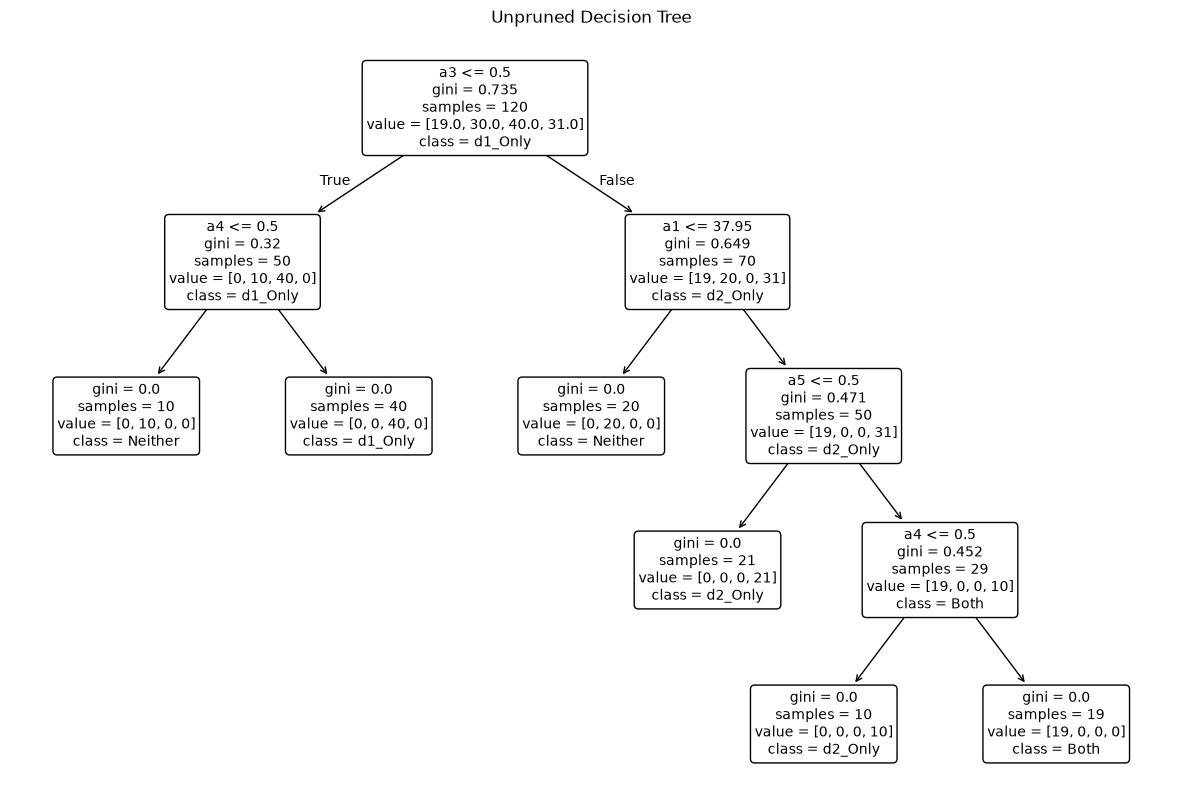

In [20]:
accute_inflam['Target_Powerset'] = accute_inflam['d1'].astype(str) + "_" + accute_inflam['d2'].astype(str)

label_powerset = {
    '0_0': 'Neither',
    '1_0': 'd1_Only',
    '0_1': 'd2_Only',
    '1_1': 'Both'
}
accute_inflam['Target_Label'] = accute_inflam['Target_Powerset'].map(label_powerset)

X = accute_inflam[feature_names]
y = accute_inflam['Target_Label']

tree = DecisionTreeClassifier(random_state=123)
tree.fit(X, y)

plt.figure(figsize=(15, 10))
plot_tree(tree, feature_names=feature_names, class_names=tree.classes_, rounded=True)
plt.title("Unpruned Decision Tree")
plt.show()

### (c) Convert the decision rules

In [ ]:
readable = {'a1': 'Temperature', 'a2': 'Nausea', 'a3': 'Lumbar Pain',
            'a4': 'Urine Pushing', 'a5': 'Micturition Pains', 'a6': 'Burning of Urethra'}
label_text = {'Neither': 'No Disease', 'd1_Only': 'Bladder Inflammation Only (d1)',
              'd2_Only': 'Nephritis Only (d2)', 'Both': 'Both d1 and d2'}

def tree_to_rules(tree_model, feature_names, class_names):
    t = tree_model.tree_
    rules = []

    def condition(name, threshold, is_left):
        if name == 'a1':  # temperature is the only continuous feature
            return f"Temperature {'<=' if is_left else '>'} {threshold:.2f}"
        return f"{readable[name]} = {'no' if is_left else 'yes'}"  # binary 0/1, split at 0.5

    def recurse(node, conds):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_names[t.feature[node]]
            thr = t.threshold[node]
            recurse(t.children_left[node], conds + [condition(name, thr, True)])
            recurse(t.children_right[node], conds + [condition(name, thr, False)])
        else:
            cls = class_names[np.argmax(t.value[node][0])]
            n = int(t.n_node_samples[node])
            lhs = ' AND '.join(conds) if conds else 'always'
            rules.append(f"IF {lhs} THEN {label_text[cls]}   [{n} samples]")

    recurse(0, [])
    for i, r in enumerate(rules, 1):
        print(f"Rule {i}: {r}")

tree_to_rules(tree, feature_names, tree.classes_)

Rule 1: IF Lumbar pain = no AND Urine pushing = no THEN No disease   [10 samples]
Rule 2: IF Lumbar pain = no AND Urine pushing = yes THEN Bladder inflammation only (d1)   [40 samples]
Rule 3: IF Lumbar pain = yes AND Temperature <= 37.95 THEN No disease   [20 samples]
Rule 4: IF Lumbar pain = yes AND Temperature > 37.95 AND Micturition pains = no THEN Nephritis only (d2)   [21 samples]
Rule 5: IF Lumbar pain = yes AND Temperature > 37.95 AND Micturition pains = yes AND Urine pushing = no THEN Nephritis only (d2)   [10 samples]
Rule 6: IF Lumbar pain = yes AND Temperature > 37.95 AND Micturition pains = yes AND Urine pushing = yes THEN Both d1 and d2   [19 samples]


### (d) Cost-Complexity Pruning

Chosen ccp_alpha = 0.0000 | leaves = 6 | CV accuracy = 0.975 | training accuracy = 1.000


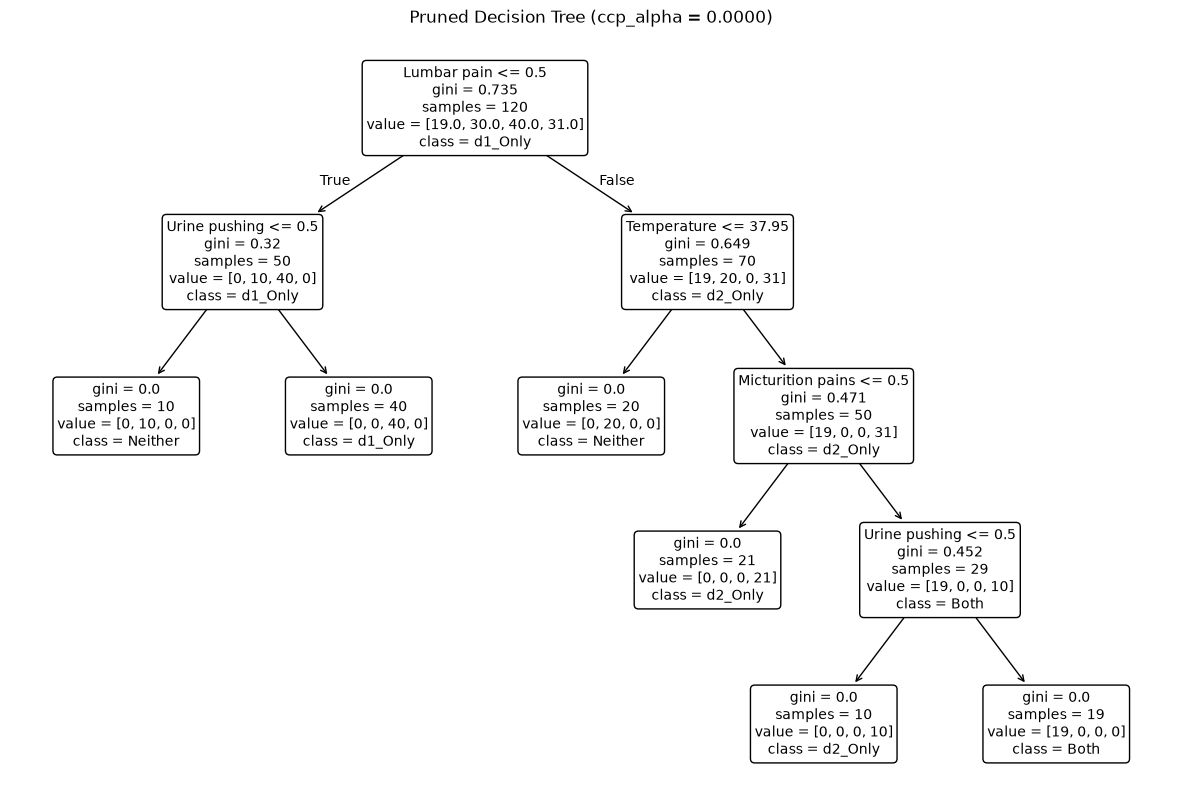

Rule 1: IF Lumbar pain = no AND Urine pushing = no THEN No disease   [10 samples]
Rule 2: IF Lumbar pain = no AND Urine pushing = yes THEN Bladder inflammation only (d1)   [40 samples]
Rule 3: IF Lumbar pain = yes AND Temperature <= 37.95 THEN No disease   [20 samples]
Rule 4: IF Lumbar pain = yes AND Temperature > 37.95 AND Micturition pains = no THEN Nephritis only (d2)   [21 samples]
Rule 5: IF Lumbar pain = yes AND Temperature > 37.95 AND Micturition pains = yes AND Urine pushing = no THEN Nephritis only (d2)   [10 samples]
Rule 6: IF Lumbar pain = yes AND Temperature > 37.95 AND Micturition pains = yes AND Urine pushing = yes THEN Both d1 and d2   [19 samples]


In [26]:
path = tree.cost_complexity_pruning_path(X, y)
ccp_alphas = path.ccp_alphas[:-1]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

rows = []
for a in ccp_alphas:
    pruned = DecisionTreeClassifier(random_state=123, ccp_alpha=a).fit(X, y)
    cv_acc = cross_val_score(DecisionTreeClassifier(random_state=123, ccp_alpha=a), X, y, cv=cv).mean()
    rows.append({'ccp_alpha': a, 'n_leaves': pruned.get_n_leaves(),
                 'train_accuracy': pruned.score(X, y), 'cv_accuracy': cv_acc})
prune_df = pd.DataFrame(rows)

best_cv = prune_df['cv_accuracy'].max()
best_alpha = prune_df.loc[np.isclose(prune_df['cv_accuracy'], best_cv), 'ccp_alpha'].max()

tree_pruned = DecisionTreeClassifier(random_state=123, ccp_alpha=best_alpha).fit(X, y)
print(f"Chosen ccp_alpha = {best_alpha:.4f} | leaves = {tree_pruned.get_n_leaves()} | "
      f"CV accuracy = {best_cv:.3f} | training accuracy = {tree_pruned.score(X, y):.3f}")

plt.figure(figsize=(15, 10))
plot_tree(tree_pruned, feature_names=[readable[f] for f in feature_names],
          class_names=tree_pruned.classes_, rounded=True)
plt.title(f"Pruned Decision Tree (ccp_alpha = {best_alpha:.4f})")
plt.show()

tree_to_rules(tree_pruned, feature_names, tree_pruned.classes_)

Cross-validation selects alpha = 0, so the minimal tree that keeps high CV accuracy is the full tree. It is already interpretable: 5 splits, 6 leaves and 6 rules that use only 4 of the 6 symptoms. Pruning further gives a simpler tree but a loss in accuracy.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [2]:
community = pd.read_csv('/Users/djovanvelasco/552_HW5/Data/communities.csv', header=None, na_values='?')

col_names = []
with open('/Users/djovanvelasco/552_HW5/Data/communities.names', 'r') as file:
    for line in file:
        if line.startswith('@attribute'):
            column_name = line.split()[1] 
            col_names.append(column_name)

community.columns = col_names

#Drop non-predictive features
non_predictive = ['state', 'county', 'community', 'communityname', 'fold']
community = community.drop(columns=[col for col in non_predictive if col in community.columns])

#Drop columns with > 80% missing values
missing_percentages = community.isnull().mean()
cols_to_drop = missing_percentages[missing_percentages > 0.80].index
community = community.drop(columns=cols_to_drop)

train_df = community.iloc[:1495].copy()
test_df = community.iloc[1495:].copy()

train_x = train_df.drop(columns=['ViolentCrimesPerPop'])
train_y = train_df['ViolentCrimesPerPop']
test_x = test_df.drop(columns=['ViolentCrimesPerPop'])
test_y = test_df['ViolentCrimesPerPop']

### (b) Missing values

In [3]:
mice_impute = IterativeImputer(random_state=123, max_iter=10)

train_x_imp = pd.DataFrame(
    mice_impute.fit_transform(train_x),
    columns=train_x.columns
)
test_x_imp = pd.DataFrame(
    mice_impute.transform(test_x),
    columns=test_x.columns
)

### (c) Plot a correlation matrix

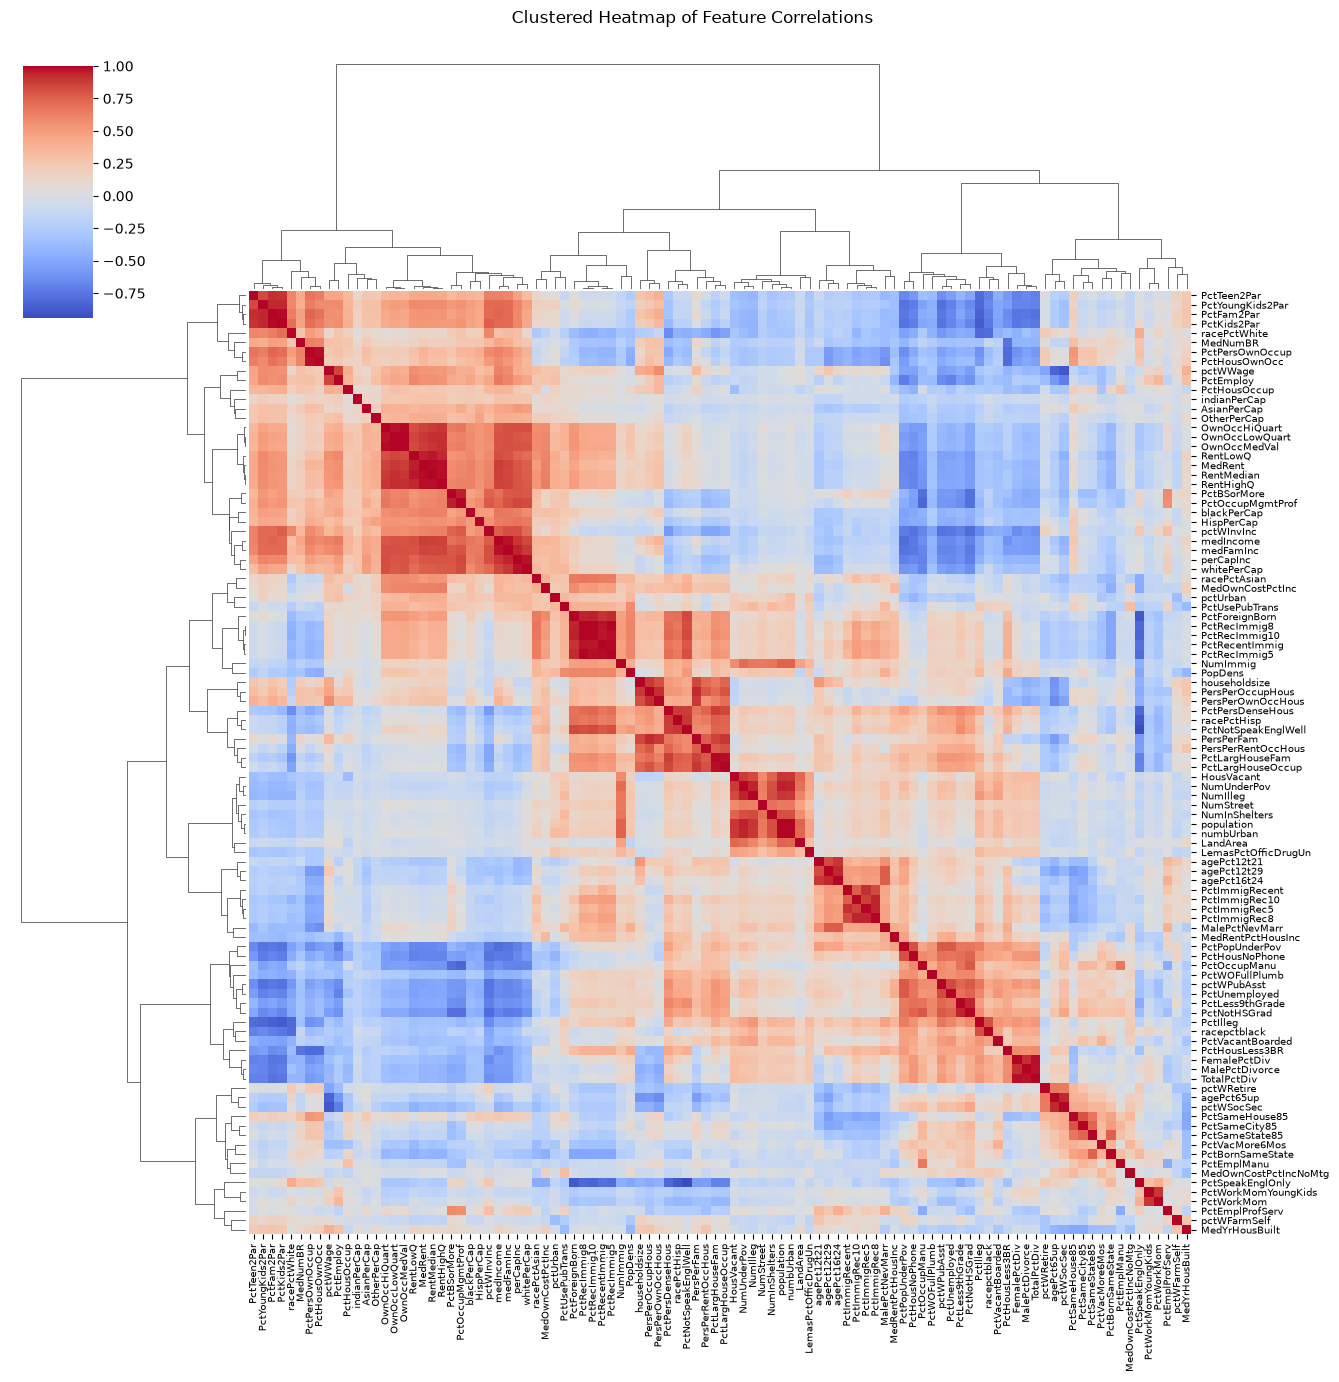

In [9]:
corr_matrix = train_x_imp.corr()
distances = pdist(corr_matrix, metric='euclidean')
linkage_matrix = fastcluster.linkage(distances, method='ward')
clustermap = sns.clustermap(corr_matrix,row_linkage=linkage_matrix,col_linkage=linkage_matrix,cmap='coolwarm',annot=False,figsize=(14, 14), 
                            xticklabels=True, yticklabels=True)
clustermap.ax_heatmap.tick_params(axis='x', labelsize=7)
clustermap.ax_heatmap.tick_params(axis='y', labelsize=7)
clustermap.fig.suptitle("Clustered Heatmap of Feature Correlations ", y=1.02)
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [ ]:
cv_series = train_x_imp.std() / (train_x_imp.mean() + 1e-8)
cv_series.sort_values(ascending=False, inplace=True)
# Display the top 10 features with the highest coefficient of variation for space
cv_series[:10]

NumStreet              4.292921
NumInShelters          3.470951
NumIlleg               3.058964
NumImmig               2.926634
LemasPctOfficDrugUn    2.552945
NumUnderPov            2.342443
population             2.241104
numbUrban              2.038461
HousVacant             1.968467
LandArea               1.645408
dtype: float64

### (e) Scatter plots and box plots for highest CV features

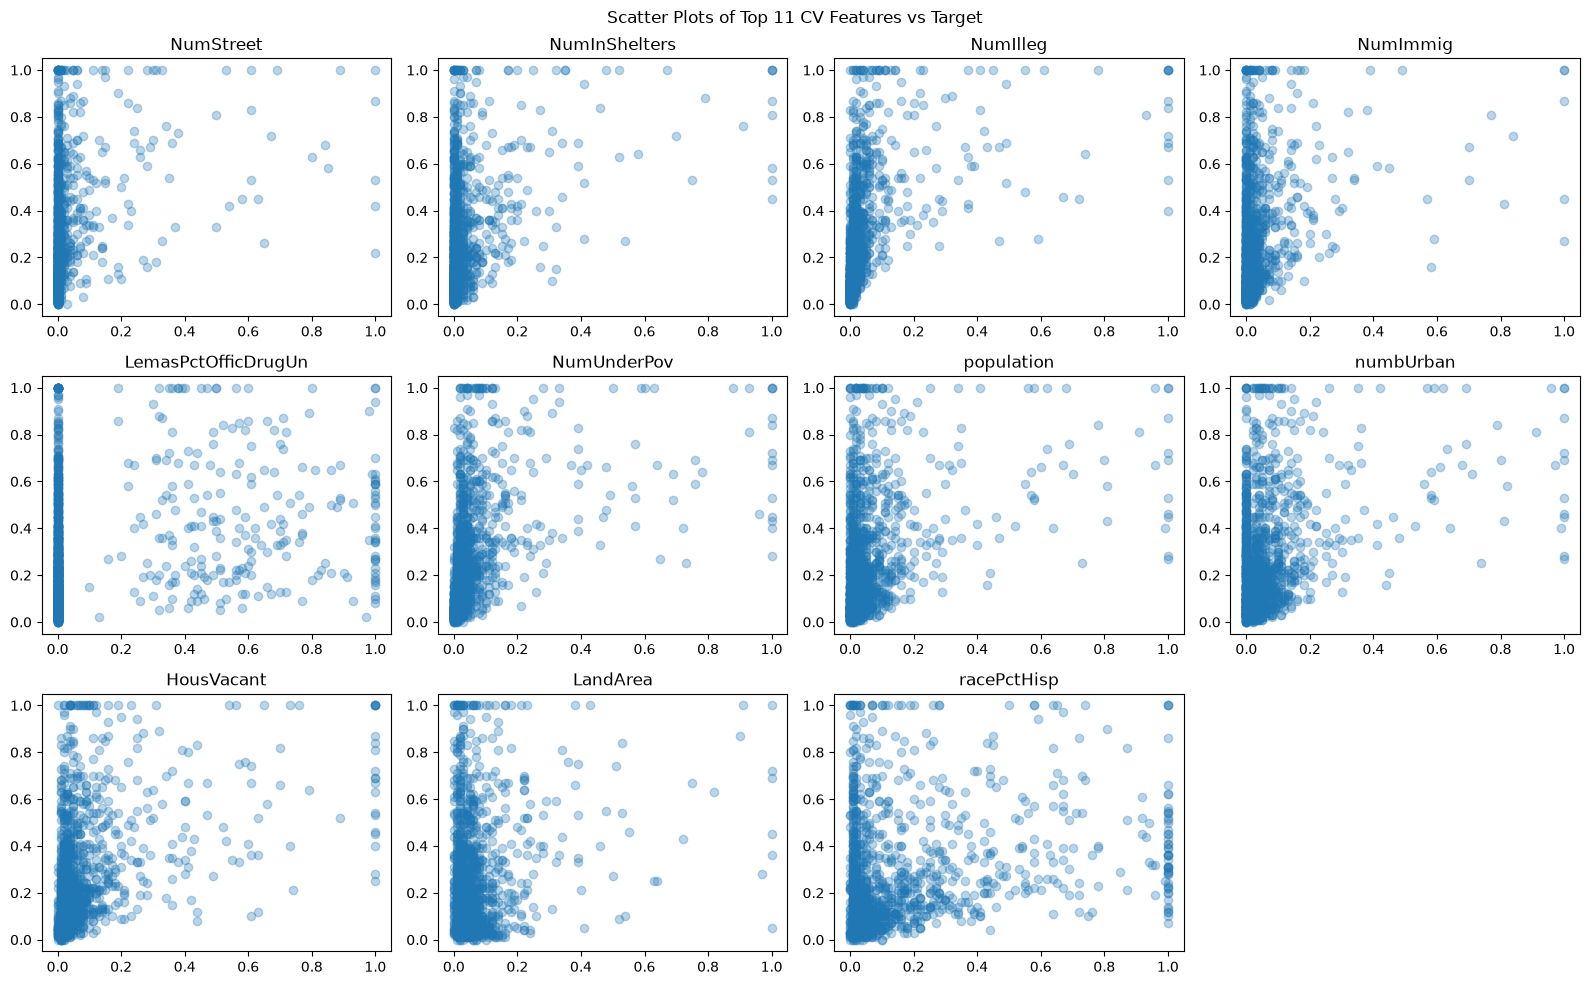

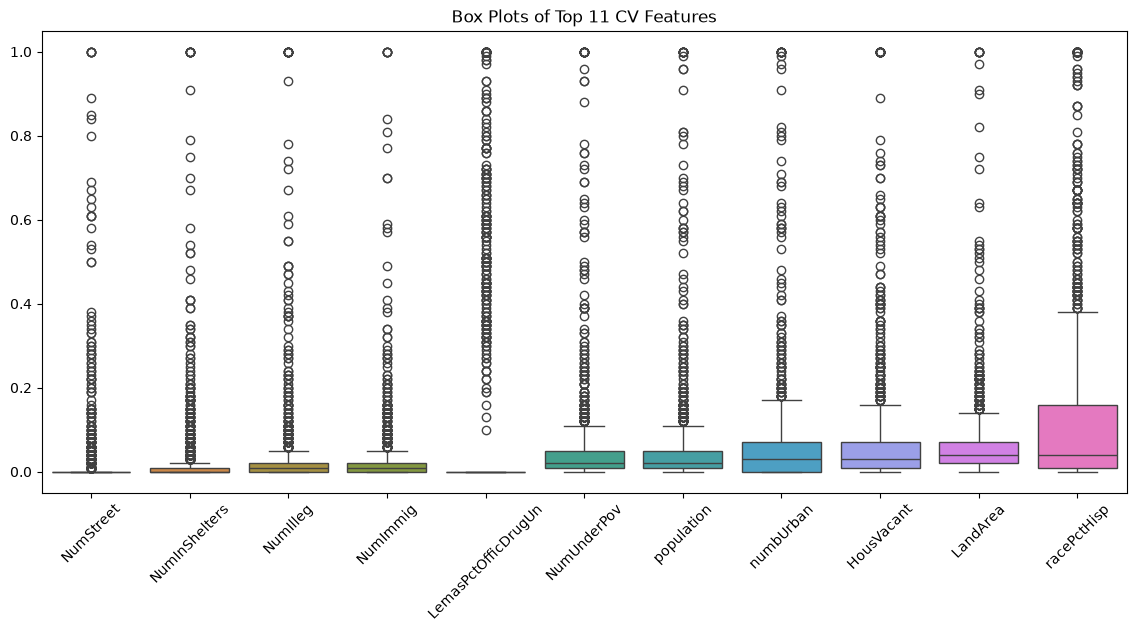

In [29]:
num_features = int(np.floor(np.sqrt(128)))
top_cv_features = cv_series.nlargest(num_features).index
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
fig.suptitle(f"Scatter Plots of Top {num_features} CV Features vs Target")
for i, feature in enumerate(top_cv_features):
    ax = axes[i // 4, i % 4]
    ax.scatter(train_x_imp[feature], train_y, alpha=0.3)
    ax.set_title(feature)
axes[2, 3].axis('off') 
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))
sns.boxplot(data=train_x_imp[top_cv_features])
plt.title(f"Box Plots of Top {num_features} CV Features")
plt.xticks(rotation=45)
plt.show()

No, we cannot tell from scatter and box plots alone. The scatter plots have most points are clustered up near and the box plots show the features are heavily right-skewed. NumIlleg, racePctHisp and HousVacant show a weak upward trend but no clear linear pattern. Without testing we can get an idea of what features may be important through correlation but can't judge significance.

### (f) Fit a linear model

In [18]:
lin_model = LinearRegression()
lin_model.fit(train_x_imp, train_y)
y_pred_lin = lin_model.predict(test_x_imp)
mse_lin = mean_squared_error(test_y, y_pred_lin)
print(f"Linear Regression Test MSE: {mse_lin:.4f}")

Linear Regression Test MSE: 0.0178


### (g) Fit a ridge regression model

In [11]:
scaler = StandardScaler()
train_x_std = pd.DataFrame(scaler.fit_transform(train_x_imp), columns=train_x_imp.columns)
test_x_std = pd.DataFrame(scaler.transform(test_x_imp), columns=test_x_imp.columns)

alphas = np.logspace(-3, 3, 100)
ridge = RidgeCV(alphas=alphas, cv=5)
ridge.fit(train_x_std, train_y)
mse_ridge = mean_squared_error(test_y, ridge.predict(test_x_std))
print(f"Ridge Test MSE: {mse_ridge:.4f}, Optimal Lambda: {ridge.alpha_:.4f}")

Ridge Test MSE: 0.0174, Optimal Lambda: 40.3702


### (h) Fit a LASSO model

In [31]:
lasso_unstd = LassoCV(cv=5, max_iter=10000, random_state=123)
lasso_unstd.fit(train_x_imp, train_y)
mse_lasso_unstd = mean_squared_error(test_y, lasso_unstd.predict(test_x_imp))
selected_vars_unstd = train_x_imp.columns[lasso_unstd.coef_ != 0]

print(f"Unstandardized LASSO Test MSE: {mse_lasso_unstd:.4f}")
print(f"Vars Selected (Unstd): {len(selected_vars_unstd)}")
print(list(selected_vars_unstd))

lasso_std = LassoCV(cv=5, max_iter=10000, random_state=123)
lasso_std.fit(train_x_std, train_y)
mse_lasso_std = mean_squared_error(test_y, lasso_std.predict(test_x_std))
selected_vars_std = train_x_std.columns[lasso_std.coef_ != 0]
print(f"\nStandardized LASSO Test MSE: {mse_lasso_std:.4f}")
print(f"Vars Selected (Std): {len(selected_vars_std)}")
print(list(selected_vars_std))

print(f"\nSelected only without standardization: {sorted(set(selected_vars_unstd) - set(selected_vars_std))}")
print(f"Selected only with standardization:    {sorted(set(selected_vars_std) - set(selected_vars_unstd))}")

Unstandardized LASSO Test MSE: 0.0176
Vars Selected (Unstd): 67
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'numbUrban', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMt

The two models have the same test MSE and select almost the same variables 67 vs. 66, having 65 variables. Without standardization LASSO keeps numbUrban and PctImmigRecent; with standardization it keeps population instead of numbUrban. Both lasso models perfrom slightly worse than the ridge. 

### (i) Fit a PCR model

In [15]:
pcr = Pipeline([
    ('pca', PCA()),
    ('lr', LinearRegression())
])
param_grid = {'pca__n_components': np.arange(1, train_x_std.shape[1] + 1)}
pcr_cv = GridSearchCV(pcr, param_grid, cv=5, scoring='neg_mean_squared_error')
pcr_cv.fit(train_x_std, train_y)
mse_pcr = mean_squared_error(test_y, pcr_cv.predict(test_x_std))
print(f"PCR Test MSE: {mse_pcr:.4f}, Optimal Components: {pcr_cv.best_params_['pca__n_components']}")

PCR Test MSE: 0.0182, Optimal Components: 78


### (j) Fit a boosting tree

In [17]:
xgb_model = xgb.XGBRegressor(random_state=42, objective='reg:squarederror')
xgb_param_grid = {'reg_alpha': np.logspace(-3, 3, 7)}

xgb_cv = GridSearchCV(xgb_model, xgb_param_grid, cv=5, scoring='neg_mean_squared_error')
xgb_cv.fit(train_x_imp, train_y)
mse_xgb = mean_squared_error(test_y, xgb_cv.predict(test_x_imp))
print(f"XGBoost Test MSE: {mse_xgb:.4f}, Optimal Alpha: {xgb_cv.best_params_['reg_alpha']:.4f}")

XGBoost Test MSE: 0.0184, Optimal Alpha: 1.0000


All models have close testing MSE values. Overall the ridge model achieves the lowest and we see across the board that the linear models perfrom better than pcr and xgboost. 

In [ ]:
%cd /Users/djovanvelasco/552_HW5
!touch README.md .gitignore requirements.txt Data/.gitkeep
!git init
!git add .
!git commit -m "Initial commit"
!git branch -M main
!git remote add origin https://github.com/Djovan-Velasco/552_hw5_repo
!git push -u origin main